## 전략 노트북입니다

In [1]:
# 모듈 임포트 셀
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
plt.rcParams["font.family"] = "AppleGothic" # 한글 깨짐 방지
plt.rcParams["axes.unicode_minus"] = False
os.makedirs("../outputs", exist_ok=True)
MIN_GROUP = 100   # 세그먼트 비율을 볼 때 필요한 최소 기업 수

In [3]:
# 데이터 불러오기. pred_test는 model 노트북이 저장한 평가 데이터 예측 확률 (model.ipynb를 먼저 실행해야 함)
df = pd.read_csv("../data/clean.csv", encoding="utf-8-sig")
pred = pd.read_csv("../outputs/pred_test.csv", index_col=0, encoding="utf-8-sig")
pred = pred[["성장여부", "prob_boost"]]   # 범주 컬럼은 model에서 희귀 범주를 묶은 뒤 저장된 거라 clean.csv 것을 쓴다
importance = pd.read_csv("../outputs/importance.csv", encoding="utf-8-sig")
target_auc = pd.read_csv("../outputs/model_targets.csv", encoding="utf-8-sig").set_index("model")["test_auc"]

# csv로 읽으면 순서가 사라져서 다시 지정
order = df.groupby("업력구간")["업력"].min().sort_values().index
df["업력구간"] = pd.Categorical(df["업력구간"], categories=order)
df["기업규모"] = pd.Categorical(df["기업규모"], categories=["소기업", "중기업", "중견기업", "대기업", "한시성중소기업"])
type_order = ["성장 지속가능", "성장 위험", "정체 안정", "정체 위험"]
df["유형"] = pd.Categorical(df["유형"], categories=type_order)
df["성장위험"] = (df["유형"] == "성장 위험").astype(int)

test_idx = pred.index   # 모델 평가에 쓴 기업. 규칙 평가에도 이 분할을 쓴다
print(df.shape, pred.shape)
importance.head(5)

(13389, 69) (2678, 2)


,feature,importance,std
0,업력,0.040053,0.006489
1,기업규모,0.022756,0.005699
2,22년 부가가치율,0.021157,0.003553
3,매출성장률_20_22,0.009011,0.002331
4,업종대분류,0.006375,0.002120


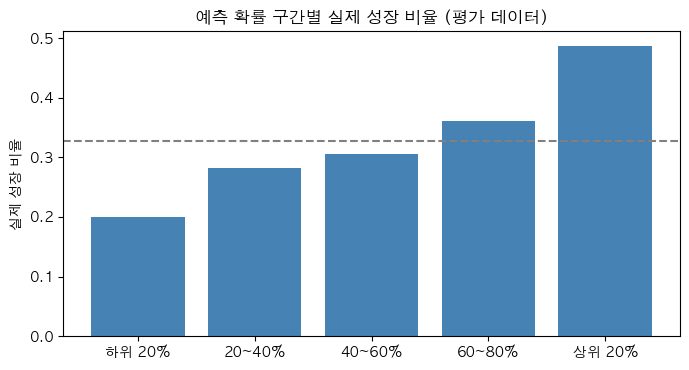

,mean,size,lift
확률구간,,,
하위 20%,0.200,536,0.610
20~40%,0.282,535,0.863
40~60%,0.306,536,0.935
60~80%,0.361,535,1.103
상위 20%,0.487,536,1.489


In [4]:
# 예측 확률 구간별 실제 성장 비율. 모델이 매긴 순위가 얼마나 믿을 만한지
pred["확률구간"] = pd.qcut(pred["prob_boost"], 5, labels=["하위 20%", "20~40%", "40~60%", "60~80%", "상위 20%"])
calib = pred.groupby("확률구간", observed=True)["성장여부"].agg(["mean", "size"])
calib["lift"] = calib["mean"] / pred["성장여부"].mean()

plt.figure(figsize=(7, 3.8))
plt.bar(calib.index.astype(str), calib["mean"], color="steelblue")
plt.axhline(pred["성장여부"].mean(), color="gray", linestyle="--")   # 전체 평균
plt.ylabel("실제 성장 비율")
plt.title("예측 확률 구간별 실제 성장 비율 (평가 데이터)")
plt.tight_layout()
plt.savefig("../outputs/strategy_calibration.png")
plt.show()
calib.round(3)

In [5]:
# 상위 20%와 하위 20% 기업의 특성 비교
cols = ["업력", "22년 부가가치율", "매출성장률_20_22", "22년 부채비율", "22년 총자산회전율", "22년 총자산"]
joined = pred.join(df[cols + ["기업규모"]])
top = joined[joined["확률구간"] == "상위 20%"]
bottom = joined[joined["확률구간"] == "하위 20%"]

compare = pd.DataFrame({"상위 20%": top[cols].median(), "하위 20%": bottom[cols].median()})
compare.loc["실제 성장 비율"] = [top["성장여부"].mean(), bottom["성장여부"].mean()]
print("기업규모 비율")
print(pd.crosstab(joined["확률구간"], joined["기업규모"], normalize="index").loc[["상위 20%", "하위 20%"]].round(2))
compare.round(2)

기업규모 비율
기업규모     소기업   중기업  중견기업  대기업  한시성중소기업
확률구간                                  
상위 20%  0.60  0.38  0.02  0.0      0.0
하위 20%  0.69  0.29  0.01  0.0      0.0


,상위 20%,하위 20%
업력,7.00,18.00
22년 부가가치율,26.15,10.10
매출성장률_20_22,1.08,-0.12
22년 부채비율,2.13,1.00
22년 총자산회전율,0.87,0.51
22년 총자산,35.00,45.00
실제 성장 비율,0.49,0.20


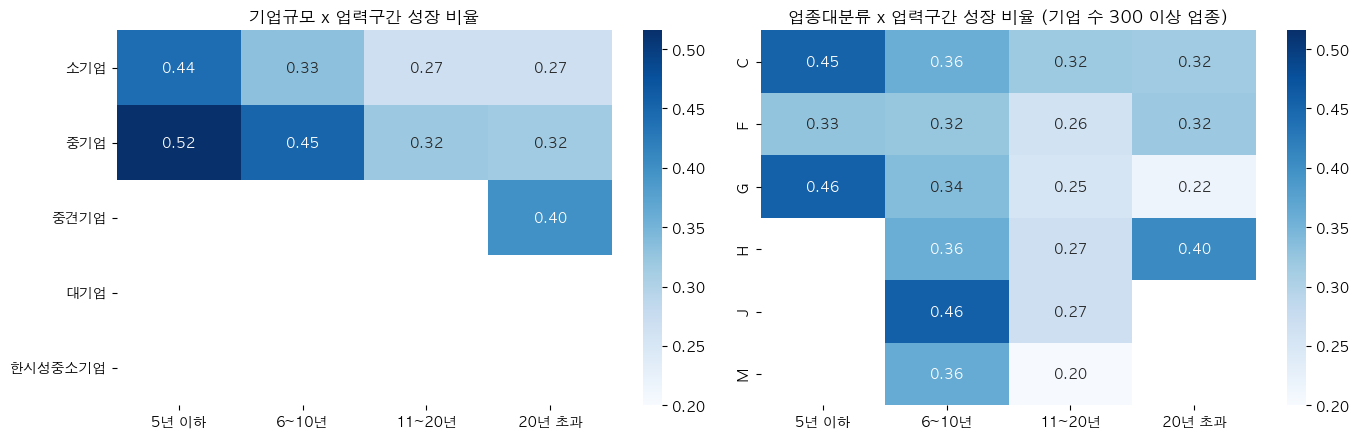

In [6]:
# 세그먼트별 성장 비율. 기업규모 x 업력구간, 업종대분류 x 업력구간
def segment_table(data, row, col, value="성장여부"):
    rate = data.pivot_table(index=row, columns=col, values=value, aggfunc="mean", observed=True)
    size = data.pivot_table(index=row, columns=col, values=value, aggfunc="size", observed=True)
    return rate.where(size >= MIN_GROUP)   # 기업 수 적은 칸은 비움

big_ind = df["업종대분류"].value_counts()
big_ind = big_ind[big_ind >= 300].index
sub = df[df["업종대분류"].isin(big_ind)]

seg_size = segment_table(df, "기업규모", "업력구간")
seg_ind = segment_table(sub, "업종대분류", "업력구간")
vmax = max(seg_size.max().max(), seg_ind.max().max())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(seg_size, annot=True, fmt=".2f", cmap="Blues", vmin=0.2, vmax=vmax, ax=axes[0])
axes[0].set_title("기업규모 x 업력구간 성장 비율")
sns.heatmap(seg_ind, annot=True, fmt=".2f", cmap="Blues", vmin=0.2, vmax=vmax, ax=axes[1])
axes[1].set_title("업종대분류 x 업력구간 성장 비율 (기업 수 300 이상 업종)")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../outputs/strategy_segment.png")
plt.show()

In [7]:
# 같은 업종 안에서 성장 기업이 갖는 공통 특성. 여 그룹 중앙값에서 부 그룹 중앙값을 뺀 값
cols = ["업력", "22년 부가가치율", "매출성장률_20_22", "22년 부채비율", "22년 총자산회전율"]
rows = []
for code in big_ind:
    part = df[df["업종대분류"] == code]
    med = part.groupby("성장여부")[cols].median()
    diff = med.loc[1] - med.loc[0]
    diff["업종대분류"] = code
    diff["기업 수"] = len(part)
    rows.append(diff)
within = pd.DataFrame(rows).set_index("업종대분류")
within.round(2)

,업력,22년 부가가치율,매출성장률_20_22,22년 부채비율,22년 총자산회전율,기업 수
업종대분류,,,,,,
C,-2.0,1.85,0.12,0.24,0.07,4992
G,-3.0,1.20,0.16,-0.22,0.00,4935
F,0.0,3.35,0.20,-0.12,0.07,1432
J,-4.0,2.70,0.09,0.00,0.08,487
H,0.0,15.10,0.03,1.02,0.26,446
M,-3.0,1.30,0.20,0.00,-0.01,344


In [8]:
# 제안용 후보군. 사전 지표만으로 고를 수 있는 단순 규칙
# 업력 10년 이하, 22년 부가가치율이 업종 중앙값 이상, 20년 대비 22년 매출이 늘어난 기업
ind_median = df.groupby("업종대분류")["22년 부가가치율"].transform("median")
rule = (df["업력"] <= 10) & (df["22년 부가가치율"] >= ind_median) & (df["매출성장률_20_22"] > 0)

# 기준값은 전체 데이터를 보고 정한 거라 전체 비율은 낙관적일 수 있음. 모델 평가 분할에서 따로 잰다
def rule_summary(data, name):
    r = rule.loc[data.index]
    return pd.DataFrame({
        "기업 수": [r.sum(), (~r).sum(), len(data)],
        "성장 비율": [data.loc[r, "성장여부"].mean(), data.loc[~r, "성장여부"].mean(), data["성장여부"].mean()],
    }, index=[name + " 후보군", name + " 나머지", name + " 전체"])

summary = pd.concat([rule_summary(df, "전체"), rule_summary(df.loc[test_idx], "평가")]).round(3)
summary.to_csv("../outputs/strategy_rule.csv", encoding="utf-8-sig")
summary

,기업 수,성장 비율
전체 후보군,1899,0.398
전체 나머지,11490,0.315
전체 전체,13389,0.327
평가 후보군,410,0.390
평가 나머지,2268,0.316
평가 전체,2678,0.327


In [9]:
# 후보군 안에서 규모별로 다시 확인. 기업 수 MIN_GROUP 이상만
by_size = df[rule].groupby("기업규모", observed=True)["성장여부"].agg(["mean", "size"])
by_size[by_size["size"] >= MIN_GROUP].round(3)

,mean,size
기업규모,,
소기업,0.374,1634
중기업,0.542,262


In [10]:
# 규칙의 각 조건을 하나씩 뺐을 때 성장 비율이 어떻게 바뀌는지 (전체 데이터)
conds = {
    "업력 10년 이하": df["업력"] <= 10,
    "부가가치율 업종 중앙값 이상": df["22년 부가가치율"] >= ind_median,
    "매출 20년 대비 22년 증가": df["매출성장률_20_22"] > 0,
}
rows = []
for name in conds:
    only = conds[name]
    rows.append({"조건": name + " 단독", "기업 수": only.sum(), "성장 비율": df.loc[only, "성장여부"].mean()})
rows.append({"조건": "세 조건 모두", "기업 수": rule.sum(), "성장 비율": df.loc[rule, "성장여부"].mean()})
pd.DataFrame(rows).round(3)

,조건,기업 수,성장 비율
0,업력 10년 이하 단독,5443,0.383
1,부가가치율 업종 중앙값 이상 단독,6689,0.356
2,매출 20년 대비 22년 증가 단독,8204,0.346
3,세 조건 모두,1899,0.398


In [11]:
# 성장 x 지속가능 유형별 특성. 어떤 기업이 성장 위험 유형에 많은지
cols = ["업력", "22년 부가가치율", "22년 부채비율", "24년 부채비율", "22년 총자산회전율", "24년 총자산회전율", "자산성장률_22_24"]
print(df["유형"].value_counts(normalize=True).round(3))
print()
print(pd.crosstab(df["유형"], df["기업규모"], normalize="index").round(2))
df.groupby("유형", observed=True)[cols].median().round(2)

유형
정체 안정      0.404
정체 위험      0.269
성장 위험      0.203
성장 지속가능    0.124
Name: proportion, dtype: float64

기업규모      소기업   중기업  중견기업  대기업  한시성중소기업
유형                                     
성장 지속가능  0.66  0.32  0.02  0.0     0.01
성장 위험    0.69  0.29  0.01  0.0     0.00
정체 안정    0.74  0.25  0.01  0.0     0.00
정체 위험    0.69  0.30  0.01  0.0     0.00


,업력,22년 부가가치율,22년 부채비율,24년 부채비율,22년 총자산회전율,24년 총자산회전율,자산성장률_22_24
유형,,,,,,,
성장 지속가능,11.0,19.7,1.0,1.00,0.55,0.58,0.29
성장 위험,11.0,20.1,2.2,2.43,0.76,0.60,0.21
정체 안정,14.0,17.7,1.0,1.00,0.58,0.76,0.00
정체 위험,12.0,16.3,3.0,3.00,0.66,0.80,0.00


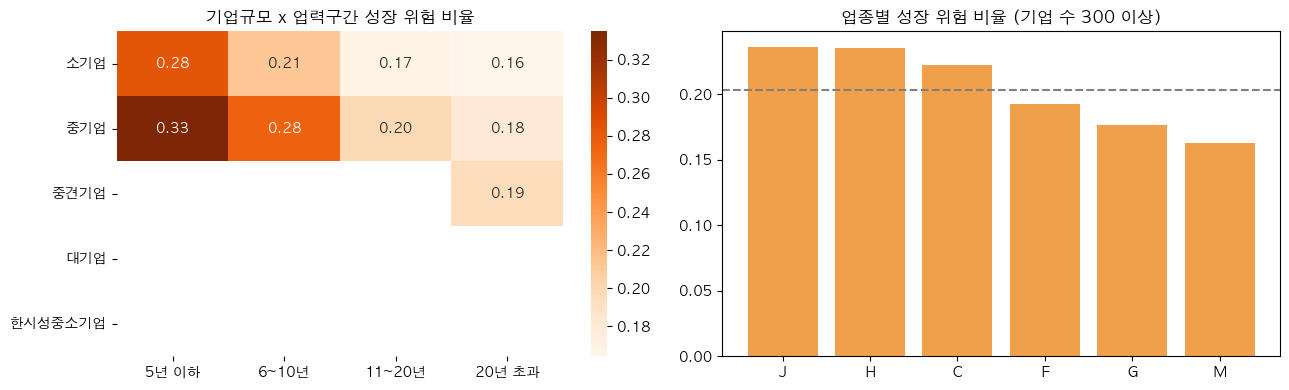

,mean,size
업종대분류,,
J,0.236,487
H,0.235,446
C,0.222,4992
F,0.193,1432
G,0.176,4935
M,0.163,344


In [12]:
# 성장 위험 비율이 높은 세그먼트. 규모 x 업력, 업종별
risk_seg = segment_table(df, "기업규모", "업력구간", value="성장위험")
risk_ind = sub.groupby("업종대분류")["성장위험"].agg(["mean", "size"]).sort_values("mean", ascending=False)   # big_ind 업종만

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(risk_seg, annot=True, fmt=".2f", cmap="Oranges", ax=axes[0])
axes[0].set_title("기업규모 x 업력구간 성장 위험 비율")
axes[0].set_xlabel("")
axes[0].set_ylabel("")
axes[1].bar(risk_ind.index, risk_ind["mean"], color="#f0a04b")
axes[1].axhline(df["성장위험"].mean(), color="gray", linestyle="--")
axes[1].set_title("업종별 성장 위험 비율 (기업 수 300 이상)")
plt.tight_layout()
plt.savefig("../outputs/strategy_risk_segment.png")
plt.show()
risk_ind.round(3)

In [13]:
# 후보군 규칙과 유형 교차. 후보군으로 골라도 성장 위험이 섞여 있는지
cross = pd.crosstab(rule.map({True: "후보군", False: "나머지"}).rename("구분"), df["유형"], normalize="index")[type_order]
cross.round(3)

유형,성장 지속가능,성장 위험,정체 안정,정체 위험
구분,,,,
나머지,0.120,0.195,0.418,0.267
후보군,0.148,0.250,0.322,0.280


In [14]:
# 대상별 제안 표. 근거 숫자는 위 셀에서 계산한 값
med = df.groupby("유형", observed=True)[["24년 부채비율", "22년 총자산회전율", "24년 총자산회전율", "자산성장률_22_24"]].median()
share = df["유형"].value_counts(normalize=True)
size_rate = df.groupby("기업규모", observed=True)["성장여부"].mean()
young_small = df[(df["기업규모"] == "소기업") & (df["업력구간"] == "5년 이하")]["성장여부"].mean()
rule_rate = summary.loc["평가 후보군", "성장 비율"]
rest_rate = summary.loc["평가 나머지", "성장 비율"]
risk_in_rule = cross.loc["후보군", "성장 위험"]
young_risk = risk_seg["5년 이하"]   # 규모별 5년 이하 성장 위험 비율
sido_rate = df.groupby("시도")["성장여부"].agg(["mean", "size"])
sido_rate = sido_rate[sido_rate["size"] >= MIN_GROUP]["mean"]
ind_rate = df.groupby("업종대분류")["성장여부"].mean()
capital_rate = df.groupby("수도권")["성장여부"].mean()

proposals = pd.DataFrame([
    {"대상": "기업", "세그먼트": "성장 위험 유형 (전체의 {:.0%})".format(share["성장 위험"]),
     "근거": "24년 부채비율 중앙값 {:.1f}, 총자산회전율 {:.2f}에서 {:.2f}까지 하락".format(med.loc["성장 위험", "24년 부채비율"], med.loc["성장 위험", "22년 총자산회전율"], med.loc["성장 위험", "24년 총자산회전율"]),
     "제안": "자산을 늘리기 전에 부가가치율과 회전율을 먼저 올린다. 부채비율 200%에 닿기 전에 투자 속도를 조절한다"},
    {"대상": "기업", "세그먼트": "성장 지속가능 유형 (전체의 {:.0%})".format(share["성장 지속가능"]),
     "근거": "부채비율 {:.1f}을 유지하면서 자산 {:.0%} 증가".format(med.loc["성장 지속가능", "24년 부채비율"], med.loc["성장 지속가능", "자산성장률_22_24"]),
     "제안": "업력 10년 이하, 부가가치율 업종 중앙값 이상이라는 공통점을 벤치마크로 삼는다"},
    {"대상": "금융기관", "세그먼트": "보증 심사 가점",
     "근거": "업력, 부가가치율, 매출성장률 규칙으로 고른 후보군 성장 비율 {:.0%}, 나머지 {:.0%} (평가 분할)".format(rule_rate, rest_rate),
     "제안": "현재 규모보다 업력과 부가가치율 조합에 가중치를 둔다. 소기업이라도 업력 10년 이하면 성장 후보로 본다"},
    {"대상": "금융기관", "세그먼트": "성장 위험 조기 경보",
     "근거": "후보군 안에서도 성장 위험이 {:.0%}. 5년 이하 기업의 성장 위험은 중기업 {:.0%}, 소기업 {:.0%}. 지속가능 예측 AUC {:.2f}, 부채 피처를 빼도 {:.2f}".format(
         risk_in_rule, young_risk["중기업"], young_risk["소기업"], target_auc["지속가능"], target_auc["지속가능 (부채 관련 피처 제외)"]),
     "제안": "성장 후보라도 22년 부채비율이 2에 가까우면 보증 한도를 단계적으로 늘리고 회전율 추이를 같이 본다"},
    {"대상": "정책기관", "세그먼트": "소기업",
     "근거": "소기업 성장 비율 {:.0%}로 가장 낮지만 5년 이하 소기업은 {:.0%}".format(size_rate["소기업"], young_small),
     "제안": "업력 5년에서 10년 사이 소기업이 중기업으로 넘어가는 구간에 지원을 집중한다"},
    {"대상": "정책기관", "세그먼트": "지역, 업종",
     "근거": "수도권 {:.0%}, 비수도권 {:.0%}. 시도 최고 {} {:.0%}. 정보통신(J) {:.0%}, 환경(E) {:.0%}".format(
         capital_rate[1], capital_rate[0], sido_rate.idxmax(), sido_rate.max(), ind_rate["J"], ind_rate["E"]),
     "제안": "비수도권 제조업과 정보통신 쪽에서 성장 후보를 찾고, 환경 업종은 성장보다 안정 지원으로 간다"},
])
proposals.to_csv("../outputs/strategy_proposals.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.max_colwidth", None)
proposals

,대상,세그먼트,근거,제안
0,기업,성장 위험 유형 (전체의 20%),"24년 부채비율 중앙값 2.4, 총자산회전율 0.76에서 0.60까지 하락",자산을 늘리기 전에 부가가치율과 회전율을 먼저 올린다. 부채비율 200%에 닿기 전에 투자 속도를 조절한다
1,기업,성장 지속가능 유형 (전체의 12%),부채비율 1.0을 유지하면서 자산 29% 증가,"업력 10년 이하, 부가가치율 업종 중앙값 이상이라는 공통점을 벤치마크로 삼는다"
2,금융기관,보증 심사 가점,"업력, 부가가치율, 매출성장률 규칙으로 고른 후보군 성장 비율 39%, 나머지 32% (평가 분할)",현재 규모보다 업력과 부가가치율 조합에 가중치를 둔다. 소기업이라도 업력 10년 이하면 성장 후보로 본다
3,금융기관,성장 위험 조기 경보,"후보군 안에서도 성장 위험이 25%. 5년 이하 기업의 성장 위험은 중기업 33%, 소기업 28%. 지속가능 예측 AUC 0.80, 부채 피처를 빼도 0.74",성장 후보라도 22년 부채비율이 2에 가까우면 보증 한도를 단계적으로 늘리고 회전율 추이를 같이 본다
4,정책기관,소기업,소기업 성장 비율 31%로 가장 낮지만 5년 이하 소기업은 44%,업력 5년에서 10년 사이 소기업이 중기업으로 넘어가는 구간에 지원을 집중한다
5,정책기관,"지역, 업종","수도권 31%, 비수도권 35%. 시도 최고 울산 48%. 정보통신(J) 39%, 환경(E) 25%","비수도권 제조업과 정보통신 쪽에서 성장 후보를 찾고, 환경 업종은 성장보다 안정 지원으로 간다"
